# Crystal-field tomography, 2D toy, learned lattice
Single-phase twinned particle. Inversion with one learned lattice and a per-voxel orientation dictionary; every tenth tilt held out. Inversions come from `run_lattice.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

from coarse2d import Coarse2D
import sim2d

## Data

In [2]:
sim2d.main("fewA")
d = np.load("runs/sim_fewA.npz")
cfg = json.loads(str(d["cfg"]))
refl = json.loads(str(d["refl"]))
data = d["I_coarse"]
lat = np.load("runs/lat_fewA_main.npz")
base = np.load("runs/lat_fewA_meanonly.npz")
true_lat = np.load("runs/lat_fewA_truelat.npz")
held = lat["held"]
train = np.setdiff1d(np.arange(len(data)), held)
crop = slice(data.shape[1] // 2 - 64, data.shape[1] // 2 + 64)

fewA: 3025 atoms, 3 grains, 60 Friedel pairs, multislice 3.9 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewA.npz


## Coarse model with true parameters

In [3]:
model = Coarse2D(
    cfg,
    d["angles"],
    s_cut=0.04,
)
pred_true = model.forward(
    torch.as_tensor(d["vbar"], dtype=torch.float64),
    torch.as_tensor(d["occ"], dtype=torch.float64),
    torch.as_tensor([e["g"] for e in refl], dtype=torch.float64),
    torch.as_tensor([complex(*e["rho"]) for e in refl], dtype=torch.complex128),
    torch.as_tensor([e["grain"] for e in refl]),
).numpy()

## Scores
Normalised squared error on the central 140 coarse pixels.

In [4]:
var = data[:, slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)].var()

def nmse(pred, idx):
    c = slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)
    return float(((pred[idx][:, c] - data[idx][:, c]) ** 2).mean() / var)

for name, pred in [
    ("mean potential only", base["pred"]),
    ("learned lattice", lat["pred"]),
    ("true lattice held fixed", true_lat["pred"]),
    ("slice model, true parameters", pred_true),
]:
    print(f"{name:30s} train {nmse(pred, train):.3f}   held-out {nmse(pred, held):.3f}")
print("learned lattice |a1|, |a2|, gamma:", np.round(lat["lattice"], 3))

mean potential only            train 0.692   held-out 1.148
learned lattice                train 0.219   held-out 1.343
true lattice held fixed        train 0.189   held-out 1.103
slice model, true parameters   train 0.175   held-out 0.482
learned lattice |a1|, |a2|, gamma: [ 2.735  2.749 59.601]


## All tilts

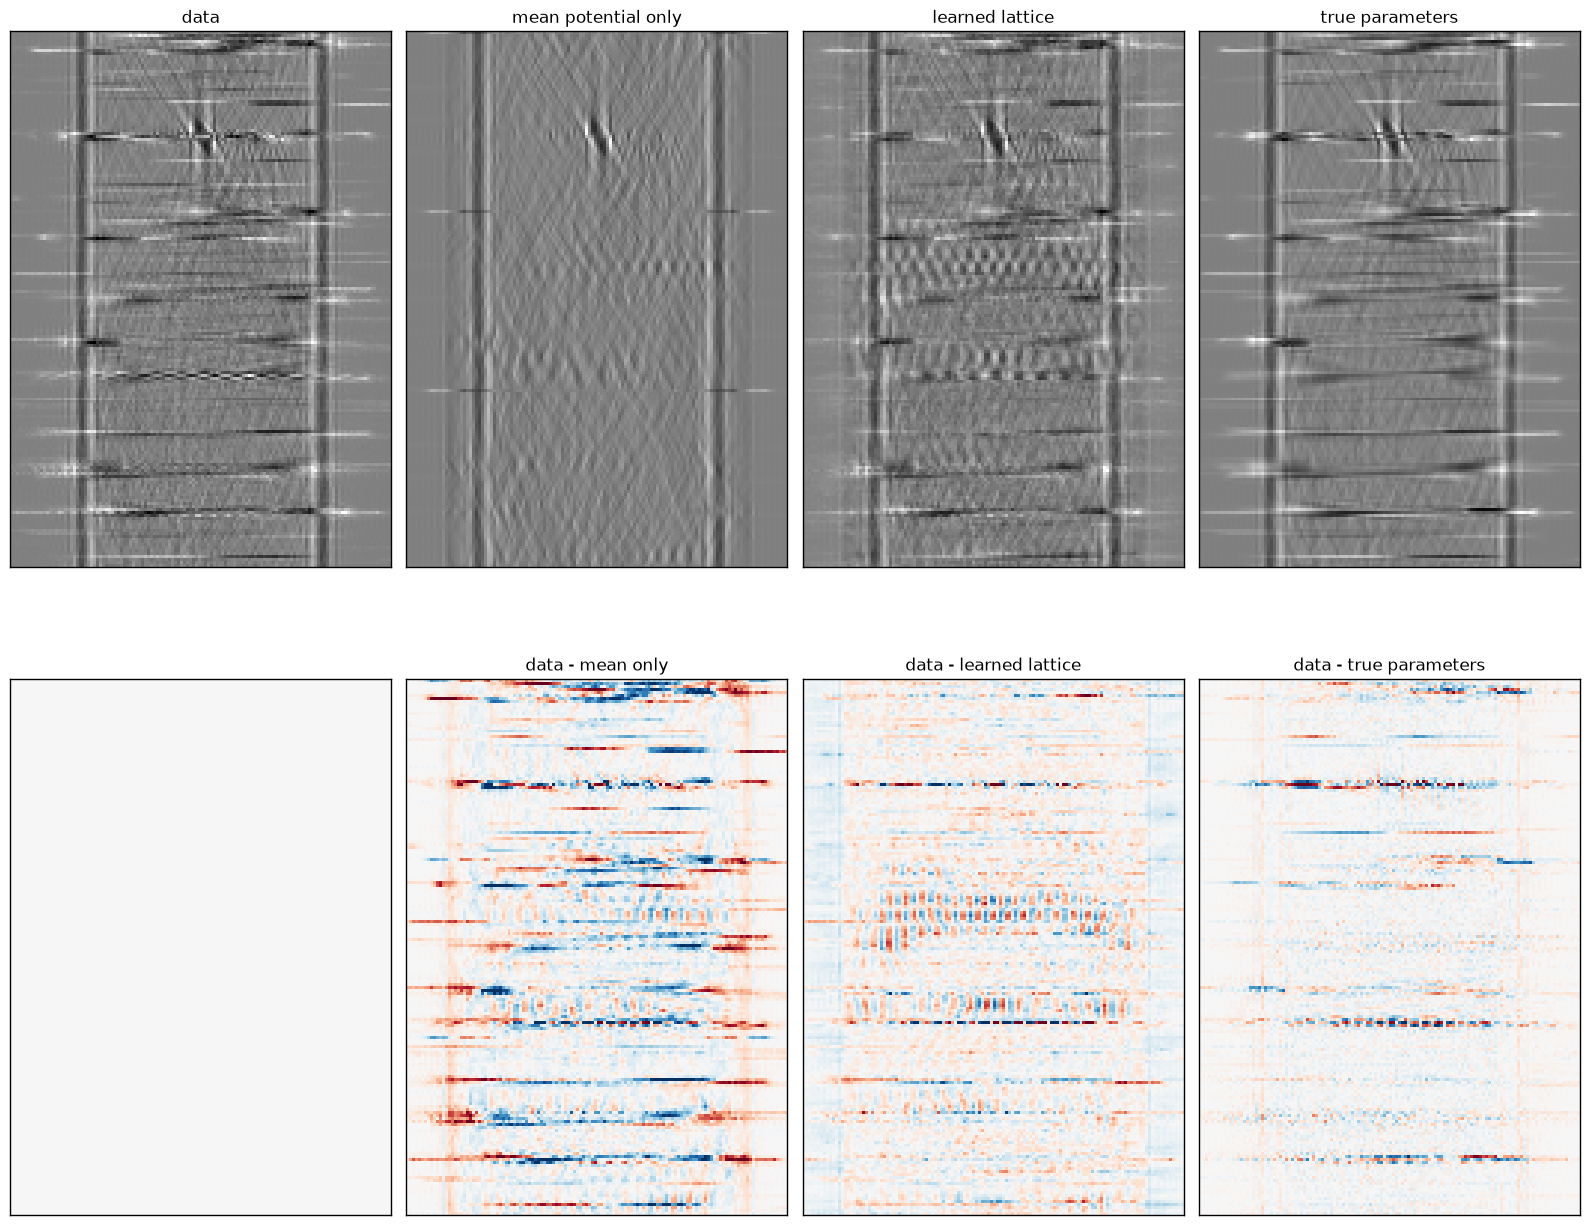

In [5]:
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop], base["pred"][:, crop], lat["pred"][:, crop], pred_true[:, crop]],
        [
            np.zeros_like(data[:, crop]),
            data[:, crop] - base["pred"][:, crop],
            data[:, crop] - lat["pred"][:, crop],
            data[:, crop] - pred_true[:, crop],
        ],
    ],
    norm=[[norm_int] * 4, [norm_diff] * 4],
    cmap=[["gray"] * 4, ["RdBu_r"] * 4],
    title=[
        ["data", "mean potential only", "learned lattice", "true parameters"],
        ["", "data - mean only", "data - learned lattice", "data - true parameters"],
    ],
    axsize=(4, 7),
);

## Held-out tilts

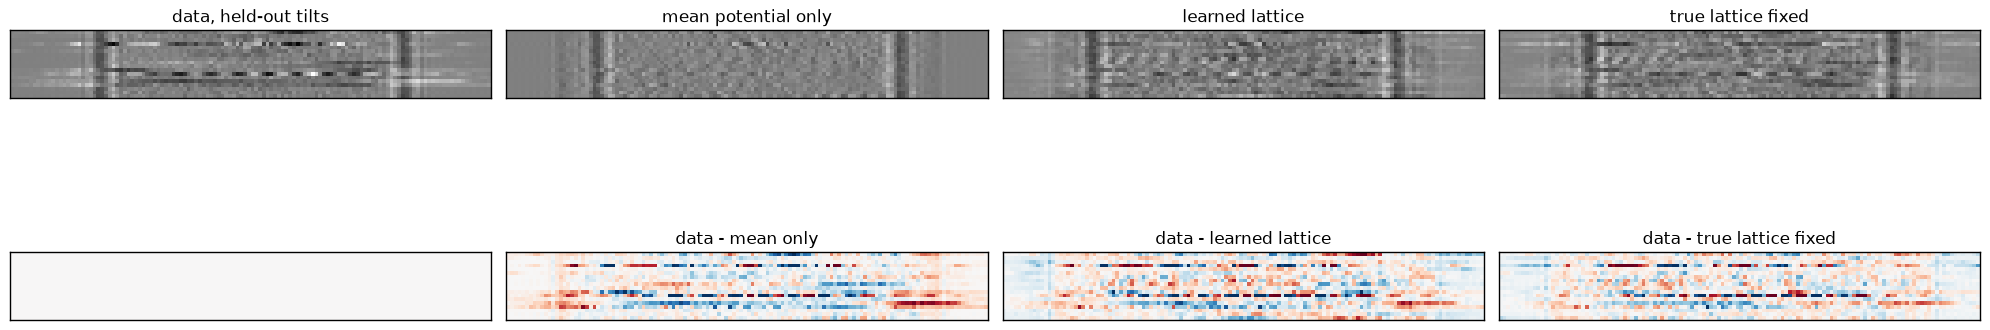

In [6]:
show_2d(
    [
        [data[held][:, crop], base["pred"][held][:, crop], lat["pred"][held][:, crop], true_lat["pred"][held][:, crop]],
        [
            np.zeros_like(data[held][:, crop]),
            data[held][:, crop] - base["pred"][held][:, crop],
            data[held][:, crop] - lat["pred"][held][:, crop],
            data[held][:, crop] - true_lat["pred"][held][:, crop],
        ],
    ],
    norm=[[norm_int] * 4, [norm_diff] * 4],
    cmap=[["gray"] * 4, ["RdBu_r"] * 4],
    title=[
        ["data, held-out tilts", "mean potential only", "learned lattice", "true lattice fixed"],
        ["", "data - mean only", "data - learned lattice", "data - true lattice fixed"],
    ],
    axsize=(5, 3),
);

## Reconstructed maps

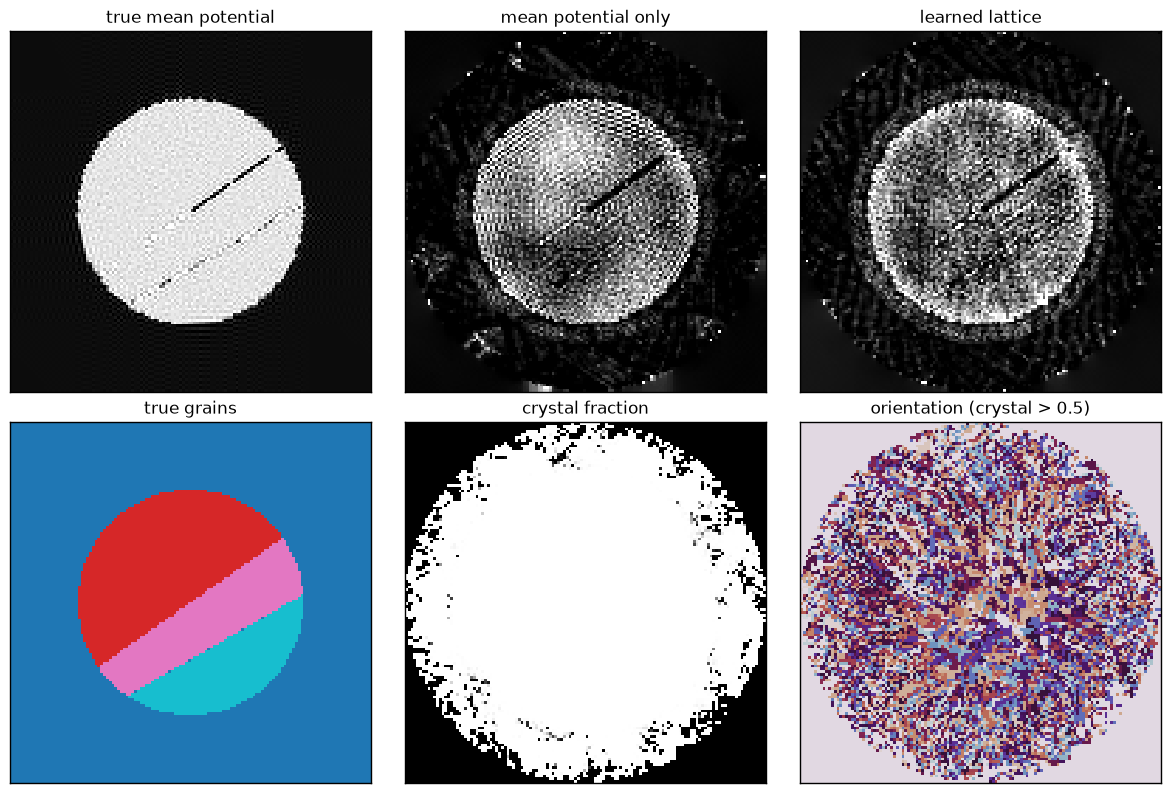

In [7]:
occ = d["occ"]
grains = np.where(occ.max(0) > 0.5, occ.argmax(0) + 1, 0)
show_2d(
    [
        [np.flipud(d["vbar"].T), np.flipud(base["vbar"].T), np.flipud(lat["vbar"].T)],
        [np.flipud(grains.T), np.flipud(lat["W_crys"].T), np.flipud(np.where(lat["W_crys"] > 0.5, lat["W_arg"], -1).T)],
    ],
    cmap=[["gray"] * 3, ["tab10", "gray", "twilight"]],
    title=[
        ["true mean potential", "mean potential only", "learned lattice"],
        ["true grains", "crystal fraction", "orientation (crystal > 0.5)"],
    ],
);